# Практика 1. S3: хранилище для данных и моделей

**Перед началом:** этот файл только для чтения и общий для всей группы.
Сохраните свою копию: **File → Save Notebook As…** →
`work/students/<ваше_имя>/01_s3.ipynb` и работайте в ней.

План:
1. Установка библиотек
2. Подключение к S3
3. Свой бакет
4. Загрузка файлов в S3
5. Просмотр содержимого
6. Скачивание файлов
7. Таблицы pandas и модели в S3
8. Копирование, удаление, ссылка для скачивания
9. **Задачи**

локальный стек:
user1
12345678


## 1. Установка библиотек

- **boto3** — официальный клиент S3 для Python (от Amazon, работает с любым S3-совместимым хранилищем)
- **s3fs** — даёт pandas читать и писать по адресу `s3://…`

На нашем сервере они уже стоят, команда просто это проверит. На своём компьютере она их установит.

In [1]:
import boto3, pandas, pyarrow, matplotlib  # зависимости уже установлены

In [2]:
import boto3
print("boto3", boto3.__version__)

boto3 1.44.6


## 2. Подключение к S3

Чтобы подключиться, нужны три вещи:

| Что | Где взять |
|---|---|
| адрес хранилища (`endpoint_url`) | внутри сервера `http://s3:9000`, снаружи `http://localhost:9000` |
| логин (`aws_access_key_id`) | `user1` (локальный стек) |
| пароль (`aws_secret_access_key`) | `12345678` |

**Пароль никогда не пишем в код** — код попадает в Git и в чужие руки. Вводим его через `getpass`:
он спрашивается при запуске ячейки и нигде не сохраняется.

In [3]:
import os

from getpass import getpass

S3_URL = os.environ["S3_ENDPOINT_URL"]     # http://s3:9000 — адрес S3 внутри сервера
print("адрес S3:", S3_URL)

адрес S3: http://s3:9000


In [4]:
S3_USER = "user1"   # <-- ЗАМЕНИТЕ на свой логин: user1 … user30
S3_PASSWORD = os.environ.get("S3_PASSWORD") or getpass(f"Пароль S3 для {S3_USER}: ")

s3 = boto3.client("s3", endpoint_url=S3_URL,
                  aws_access_key_id=S3_USER, aws_secret_access_key=S3_PASSWORD)

# проверка связи: список бакетов — вы видите только свой
for b in s3.list_buckets()["Buckets"]:
    print(b["Name"], b["CreationDate"].date())

user1 2026-11-19
mlflow 2026-11-19
airflow-logs 2026-11-19
students 2026-11-19
user2 2026-11-19
user3 2026-11-19
user4 2026-11-19
user5 2026-11-19
user6 2026-11-19
user7 2026-11-19
user8 2026-11-19
user9 2026-11-19
user10 2026-11-19
user11 2026-11-19
user12 2026-11-19
user13 2026-11-19
user14 2026-11-19
user15 2026-11-19
user16 2026-11-19
user17 2026-11-19
user18 2026-11-19
user19 2026-11-19
user20 2026-11-19
user21 2026-11-19
user22 2026-11-19
user23 2026-11-19
user24 2026-11-19
user25 2026-11-19
user26 2026-11-19
user27 2026-11-19
user28 2026-11-19
user29 2026-11-19
user30 2026-11-19


## 3. Свой бакет

Бакет — большой контейнер с уникальным именем. У каждого студента свой: **имя бакета = ваш логин** (`user7` → бакет `user7`).

Бакет уже создан для вас заранее. На учебном сервере права разграничены: вы видите и меняете **только свой бакет**, чужой отвечает `AccessDenied`. Локальный стек проще: один ключ `user1` открывает все бакеты — это единственное отличие.

In [5]:
BUCKET = S3_USER
print("мой бакет:", BUCKET)

мой бакет: user1


In [6]:
from botocore.exceptions import ClientError

def bucket_exists(name: str) -> bool:
    try:
        s3.head_bucket(Bucket=name)   # head_* — узнать, есть ли объект, не скачивая его
        return True
    except ClientError:
        return False

if not bucket_exists(BUCKET):
    s3.create_bucket(Bucket=BUCKET)
    print("создан бакет", BUCKET)
else:
    print("бакет уже есть:", BUCKET)

бакет уже есть: user1


In [7]:
# «чужой» бакет students: на сервере здесь будет AccessDenied,
# локально один ключ открывает всё — это нормально
try:
    s3.list_objects_v2(Bucket="students")
    print("локально доступ есть — один общий ключ (на сервере было бы AccessDenied)")
except ClientError as e:
    print("чужой бакет:", e.response["Error"]["Code"])

локально доступ есть — один общий ключ (на сервере было бы AccessDenied)


## 4. Загрузка файлов в S3

Три способа:

| Метод | Когда |
|---|---|
| `upload_file(путь, бакет, ключ)` | файл уже лежит на диске |
| `put_object(Bucket, Key, Body)` | данные в памяти: строка или байты |
| `upload_fileobj(файл, бакет, ключ)` | открытый файл или поток |

**Ключ** — полное имя объекта. Слеши в ключе выглядят как папки, но это просто часть имени.

In [8]:
# 4.1 файл с диска
with open("hello.txt", "w") as f:
    f.write("Привет, S3!\n")

s3.upload_file("hello.txt", BUCKET, "docs/hello.txt")
print("загружен docs/hello.txt")

загружен docs/hello.txt


In [9]:
# 4.2 строка из памяти, без файла на диске
s3.put_object(Bucket=BUCKET, Key="docs/note.txt", Body="Заметка из памяти".encode("utf-8"))
print("загружен docs/note.txt")

загружен docs/note.txt


In [10]:
# 4.3 таблица pandas -> CSV в S3
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True).frame
s3.put_object(Bucket=BUCKET, Key="data/raw/wine.csv", Body=wine.to_csv(index=False))
print("загружен data/raw/wine.csv:", wine.shape)

загружен data/raw/wine.csv: (178, 14)


In [11]:
# 4.4 картинка matplotlib -> PNG в S3 (через память, без диска)
import io
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3))
wine["alcohol"].hist(ax=ax, bins=20)
ax.set_title("Алкоголь в винах")

buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=100)
plt.close(fig)
s3.put_object(Bucket=BUCKET, Key="images/alcohol.png", Body=buf.getvalue(), ContentType="image/png")
print("загружен images/alcohol.png,", len(buf.getvalue()), "байт")

загружен images/alcohol.png, 15655 байт


## 5. Что лежит в бакете

`list_objects_v2` возвращает до 1000 объектов. `Prefix` — показать только ключи, начинающиеся с этой строки («папка»).

In [12]:
def ls(prefix: str = ""):
    resp = s3.list_objects_v2(Bucket=BUCKET, Prefix=prefix)
    for obj in resp.get("Contents", []):
        print(f'{obj["Key"]:<30} {obj["Size"]:>8} байт   {obj["LastModified"]:%Y-%m-%d %H:%M}')

ls()

airflow/2026-11-19/cancer.parquet   147750 байт   2026-11-19 20:19
airflow/2026-11-19/iris.parquet     5199 байт   2026-11-19 20:18
airflow/2026-11-19/step4/confusion_matrix.png    14891 байт   2026-11-19 20:19
airflow/2026-11-19/step4/metrics.json       62 байт   2026-11-19 20:19
airflow/2026-11-19/step4/model.joblib     3185 байт   2026-11-19 20:19
airflow/2026-11-19/step4/test.parquet    56759 байт   2026-11-19 20:18
airflow/2026-11-19/step4/train.parquet   116810 байт   2026-11-19 20:18
airflow/heartbeat/2026-11-19T200000+0000.txt       36 байт   2026-11-19 20:17
backup/reports/report_1.txt          23 байт   2026-11-19 20:17
backup/reports/report_2.txt          23 байт   2026-11-19 20:17
backup/reports/report_3.txt          23 байт   2026-11-19 20:17
data/processed/iris.parquet        5199 байт   2026-11-19 20:17
data/processed/sales.parquet   11847301 байт   2026-11-19 20:17
data/raw/iris.csv                  2777 байт   2026-11-19 20:17
data/raw/wine.csv                 12261 ба

In [13]:
ls("docs/")   # только «папка» docs

docs/hello.txt                       18 байт   2026-11-19 20:21
docs/note.txt                        32 байт   2026-11-19 20:21


In [14]:
# метаданные одного объекта, без скачивания
meta = s3.head_object(Bucket=BUCKET, Key="images/alcohol.png")
print(meta["ContentLength"], "байт,", meta["ContentType"])

15655 байт, image/png


## 6. Скачивание

| Метод | Результат |
|---|---|
| `download_file(бакет, ключ, путь)` | файл на диске |
| `get_object(Bucket, Key)["Body"].read()` | байты в памяти |

In [15]:
# 6.1 на диск
s3.download_file(BUCKET, "docs/hello.txt", "hello_downloaded.txt")
print(open("hello_downloaded.txt").read())

Привет, S3!



In [16]:
# 6.2 в память
body = s3.get_object(Bucket=BUCKET, Key="docs/note.txt")["Body"].read()
print(body.decode("utf-8"))

Заметка из памяти


In [17]:
# 6.3 CSV из S3 сразу в pandas
body = s3.get_object(Bucket=BUCKET, Key="data/raw/wine.csv")["Body"].read()
df = pd.read_csv(io.BytesIO(body))
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


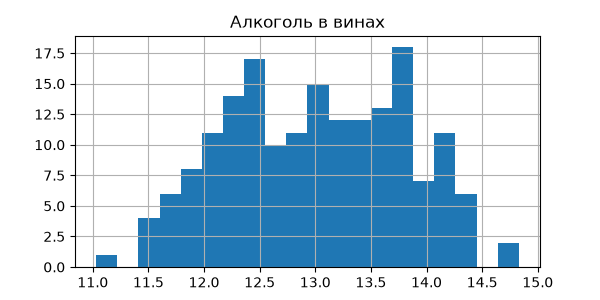

In [18]:
# 6.4 картинку из S3 — показать в ноутбуке
from IPython.display import Image
Image(s3.get_object(Bucket=BUCKET, Key="images/alcohol.png")["Body"].read())

## 7. Parquet и модели в S3

### Зачем это нужно
В ML-конвейере данные сохраняют **много раз**: сырые → очищенные → train/test → прогнозы.
Если каждый раз сохранять в CSV, возникают три проблемы:

1. **Размер.** CSV — это текст: число `300.25` занимает 6 байт, в parquet — меньше и ещё сжимается.
2. **Скорость.** CSV нужно разбирать построчно, parquet читается почти сразу.
3. **Типы теряются.** Сохранили дату в CSV — прочитали обратно **строку**. Parquet помнит, что это дата.

**Parquet** — формат таблиц, который решает все три проблемы. Поэтому в ML его используют почти везде
(в наших DAG-ах train/test тоже лежат в `.parquet`).

### Что сделаем
- **7.1** — сравним CSV и parquet на таблице продаж в **миллион строк** (как в примере с магазином из лекции);
- **7.2** — научимся класть таблицу в S3 в parquet и читать обратно: это приём, который вы будете использовать в Airflow;
- **7.3** — так же сохраним в S3 **модель**.

In [19]:
# 7.1 CSV против parquet на большой таблице (всё в памяти, в S3 пока не пишем)
import time
import numpy as np

n = 1_000_000
rng = np.random.default_rng(42)
sales = pd.DataFrame({
    "time": pd.date_range("2026-01-01", periods=n, freq="min"),   # дата и время продажи
    "store": rng.choice(["Москва", "Казань", "Сочи"], n),
    "product_id": rng.integers(1, 5000, n),
    "price": rng.normal(300, 50, n).round(2),
    "sold": rng.integers(0, 20, n),
})

csv_bytes = sales.to_csv(index=False).encode()        # таблица -> CSV (байты)
pq_buf = io.BytesIO()
sales.to_parquet(pq_buf, index=False)                  # таблица -> parquet (байты)
pq_bytes = pq_buf.getvalue()

t = time.time(); from_csv = pd.read_csv(io.BytesIO(csv_bytes)); t_csv = time.time() - t
t = time.time(); from_pq = pd.read_parquet(io.BytesIO(pq_bytes)); t_pq = time.time() - t

print(f"Размер:  CSV {len(csv_bytes)/1e6:.1f} МБ   parquet {len(pq_bytes)/1e6:.1f} МБ   (в {len(csv_bytes)/len(pq_bytes):.1f} раза меньше)")
print(f"Чтение:  CSV {t_csv:.2f} с     parquet {t_pq:.2f} с")
print("Тип колонки time после CSV:    ", from_csv["time"].dtype, " <- строка, дату надо разбирать заново")
print("Тип колонки time после parquet:", from_pq["time"].dtype)

Размер:  CSV 45.8 МБ   parquet 11.8 МБ   (в 3.9 раза меньше)
Чтение:  CSV 0.85 с     parquet 0.13 с
Тип колонки time после CSV:     object  <- строка, дату надо разбирать заново
Тип колонки time после parquet: datetime64[ns]


**Что видно:** parquet в несколько раз меньше, читается во много раз быстрее, и дата осталась датой.
Для ML это значит: меньше места в S3, быстрее задачи Airflow и нет ошибок из-за «испорченных» типов.

Ещё один плюс — можно прочитать **только нужные колонки**, не загружая всю таблицу:

In [20]:
t = time.time()
only_sold = pd.read_parquet(io.BytesIO(pq_bytes), columns=["sold"])
print(f"одна колонка из миллиона строк: {time.time() - t:.3f} с")

одна колонка из миллиона строк: 0.010 с


> На маленькой таблице (150–200 строк, как Iris или Wine) parquet может оказаться даже **больше** CSV:
> в файле есть служебная информация о колонках. Выигрыш появляется на больших данных — а в реальных задачах они большие.

### 7.2 Таблица в S3 в формате parquet и обратно
Схема всегда одна и та же, её стоит запомнить:

**сохранить:** DataFrame → `to_parquet` в буфер памяти → `put_object`<br>
**прочитать:** `get_object` → байты → `read_parquet`

In [21]:
# сохранить: DataFrame -> parquet в памяти -> S3
buf = io.BytesIO()
sales.to_parquet(buf, index=False)
s3.put_object(Bucket=BUCKET, Key="data/processed/sales.parquet", Body=buf.getvalue())

# прочитать: S3 -> байты -> DataFrame
body = s3.get_object(Bucket=BUCKET, Key="data/processed/sales.parquet")["Body"].read()
sales_back = pd.read_parquet(io.BytesIO(body))

print("в S3:", s3.head_object(Bucket=BUCKET, Key="data/processed/sales.parquet")["ContentLength"] // 1_000_000, "МБ")
print("прочитали", sales_back.shape, "| совпадает с исходной:", sales_back.equals(sales))

в S3: 11 МБ
прочитали (1000000, 5) | совпадает с исходной: True


### 7.3 Модель в S3
Модель sklearn — это объект Python, а S3 хранит байты. `joblib.dump` превращает модель в байты,
`joblib.load` — обратно. Так модель, обученную в одной задаче Airflow, загружает следующая задача
или сервис прогнозов на другом компьютере.

In [22]:
import joblib
from sklearn.linear_model import LogisticRegression

X, y = wine.drop(columns="target"), wine["target"]
model = LogisticRegression(max_iter=5000).fit(X, y)

buf = io.BytesIO()
joblib.dump(model, buf)                                         # модель -> байты
s3.put_object(Bucket=BUCKET, Key="models/logreg.joblib", Body=buf.getvalue())

body = s3.get_object(Bucket=BUCKET, Key="models/logreg.joblib")["Body"].read()
loaded = joblib.load(io.BytesIO(body))                          # байты -> модель
print("прогноз загруженной модели:", loaded.predict(X.head(5)))

прогноз загруженной модели: [0 0 0 0 0]


## 8. Копирование, удаление, ссылка для скачивания

In [23]:
# 8.1 копия внутри S3 (данные не проходят через ваш компьютер)
s3.copy_object(Bucket=BUCKET, Key="backup/wine.csv",
               CopySource={"Bucket": BUCKET, "Key": "data/raw/wine.csv"})
ls("backup/")

backup/reports/report_1.txt          23 байт   2026-11-19 20:17
backup/reports/report_2.txt          23 байт   2026-11-19 20:17
backup/reports/report_3.txt          23 байт   2026-11-19 20:17
backup/wine.csv                   12261 байт   2026-11-19 20:21


In [24]:
# 8.2 удаление
s3.delete_object(Bucket=BUCKET, Key="backup/wine.csv")
ls("backup/")
print("после удаления в backup/ пусто")

backup/reports/report_1.txt          23 байт   2026-11-19 20:17
backup/reports/report_2.txt          23 байт   2026-11-19 20:17
backup/reports/report_3.txt          23 байт   2026-11-19 20:17
после удаления в backup/ пусто


In [25]:
# 8.3 временная ссылка на файл (presigned URL): открывается в браузере без пароля, пока не истечёт
public = boto3.client("s3", endpoint_url="http://localhost:9000",   # адрес, видимый снаружи
                      aws_access_key_id=S3_USER, aws_secret_access_key=S3_PASSWORD)
url = public.generate_presigned_url("get_object",
                                    Params={"Bucket": BUCKET, "Key": "images/alcohol.png"},
                                    ExpiresIn=600)   # 10 минут
print(url)

http://localhost:9000/user1/images/alcohol.png?AWSAccessKeyId=user1&Signature=29iOSOR7pYRwiArEmU4QQQ1JPQQ%3D&Expires=1795120312


## Шпаргалка

| Действие | Команда |
|---|---|
| подключиться | `s3 = boto3.client("s3", endpoint_url=..., aws_access_key_id=..., aws_secret_access_key=...)` |
| бакеты | `s3.list_buckets()`, `s3.create_bucket(Bucket=b)` |
| загрузить | `s3.upload_file(путь, b, key)`, `s3.put_object(Bucket=b, Key=key, Body=...)` |
| список | `s3.list_objects_v2(Bucket=b, Prefix="docs/")` |
| скачать | `s3.download_file(b, key, путь)`, `s3.get_object(Bucket=b, Key=key)["Body"].read()` |
| метаданные | `s3.head_object(Bucket=b, Key=key)` |
| копировать / удалить | `s3.copy_object(...)`, `s3.delete_object(Bucket=b, Key=key)` |
| ссылка | `s3.generate_presigned_url("get_object", Params=..., ExpiresIn=600)` |

---
# 9. Задачи

Все задачи — в **своём бакете** `BUCKET`. Проверяйте результат через `ls()` и в веб-консоли S3.

### Задача 1. Iris в S3
Загрузите датасет Iris (`sklearn.datasets.load_iris(as_frame=True).frame`) в свой бакет как CSV
по ключу `data/raw/iris.csv`. Выведите содержимое «папки» `data/raw/`.

In [26]:
from sklearn.datasets import load_iris
iris=load_iris(as_frame=True).frame
s3.put_object(Bucket=BUCKET,Key='data/raw/iris.csv',Body=iris.to_csv(index=False).encode());ls('data/raw/')

data/raw/iris.csv                  2777 байт   2026-11-19 20:21
data/raw/wine.csv                 12261 байт   2026-11-19 20:21


### Задача 2. Несколько файлов в цикле
Создайте 3 текстовых отчёта `reports/report_1.txt` … `reports/report_3.txt`
(в каждом — строка «Отчёт номер N»). Потом одной командой получите список `reports/`
и посчитайте **общий размер** этих файлов в байтах.

In [27]:
for k in range(1,4):
    s3.put_object(Bucket=BUCKET,Key=f'reports/report_{k}.txt',Body=f'Отчёт номер {k}'.encode())
objects=s3.list_objects_v2(Bucket=BUCKET,Prefix='reports/')['Contents']
print([r['Key'] for r in objects],sum(r['Size'] for r in objects),'байт')

['reports/report_1.txt', 'reports/report_2.txt', 'reports/report_3.txt'] 69 байт


### Задача 3. Скачать и проверить
Скачайте `data/raw/iris.csv` **на диск** в файл `iris_local.csv`, прочитайте его pandas
и проверьте, что строк столько же, сколько в исходном датасете (150).

In [28]:
s3.download_file(BUCKET,'data/raw/iris.csv','iris_local.csv'); back=pd.read_csv('iris_local.csv'); assert len(back)==len(iris)==150; print(back.shape)

(150, 5)


### Задача 4. Parquet туда и обратно
Сохраните Iris в S3 в формате **parquet** по ключу `data/processed/iris.parquet`,
прочитайте обратно в DataFrame и проверьте `.equals()`. Сравните размеры CSV и parquet (`head_object`).
Какой файл меньше и почему? Что изменится для таблицы в миллион строк?

In [29]:
key='data/processed/iris.parquet'; s3.put_object(Bucket=BUCKET,Key=key,Body=iris.to_parquet(index=False)); assert pd.read_parquet(io.BytesIO(s3.get_object(Bucket=BUCKET,Key=key)['Body'].read())).equals(iris)
print({k:s3.head_object(Bucket=BUCKET,Key=k)['ContentLength'] for k in ['data/raw/iris.csv',key]});print('На маленькой таблице метаданные parquet дороги; на миллионе строк сжатие окупилось (раздел 7).')

{'data/raw/iris.csv': 2777, 'data/processed/iris.parquet': 5199}
На маленькой таблице метаданные parquet дороги; на миллионе строк сжатие окупилось (раздел 7).


### Задача 5. График и ссылка
Постройте диаграмму рассеяния Iris (`petal length (cm)` против `petal width (cm)`, цвет — `target`),
сохраните её в S3 как `images/iris_scatter.png` **без записи на диск** и получите ссылку на 10 минут.
Откройте ссылку в браузере.

http://localhost:9000/user1/images/iris_scatter.png?AWSAccessKeyId=user1&Signature=xyN9P8CpnL6KT9CPFq%2FDNUz%2BUJ8%3D&Expires=1795120312


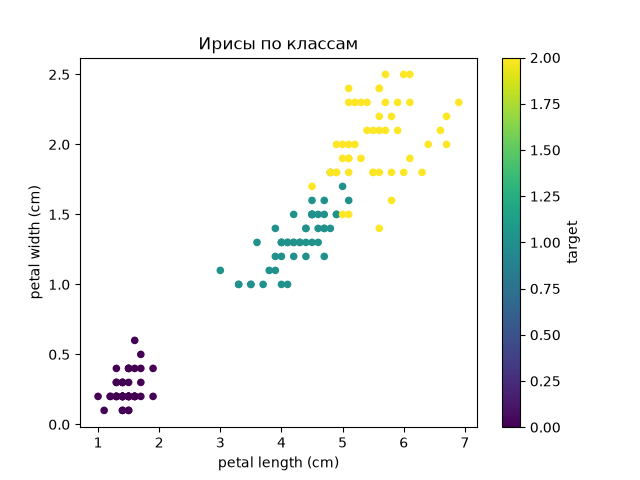

In [30]:
fig,ax=plt.subplots(); iris.plot.scatter('petal length (cm)','petal width (cm)',c='target',colormap='viridis',ax=ax); ax.set_title('Ирисы по классам'); buf=io.BytesIO(); fig.savefig(buf,format='png'); plt.close(fig)
key='images/iris_scatter.png'; s3.put_object(Bucket=BUCKET,Key=key,Body=buf.getvalue(),ContentType='image/png'); print(public.generate_presigned_url('get_object',Params={'Bucket':BUCKET,'Key':key},ExpiresIn=600)); display(Image(buf.getvalue()))

### Задача 6. Модель в S3
Обучите `RandomForestClassifier(random_state=42)` на Iris, сохраните модель в `models/iris_rf.joblib`,
загрузите её обратно и посчитайте accuracy загруженной модели на всём датасете.

In [31]:
from sklearn.ensemble import RandomForestClassifier
X,y=iris.drop(columns='target'),iris.target
rf=RandomForestClassifier(random_state=42).fit(X,y); buf=io.BytesIO();joblib.dump(rf,buf);key='models/iris_rf.joblib';s3.put_object(Bucket=BUCKET,Key=key,Body=buf.getvalue()); restored=joblib.load(io.BytesIO(s3.get_object(Bucket=BUCKET,Key=key)['Body'].read())); print('Accuracy на обучающих данных:',restored.score(X,y))

Accuracy на обучающих данных: 1.0


### Задача 7 (со звёздочкой). Резервная копия «папки»
Напишите функцию `backup(prefix)`, которая копирует **все** объекты с ключами на `prefix`
в `backup/<prefix>…` через `copy_object`. Сделайте резервную копию `reports/`,
затем удалите оригиналы из `reports/` и покажите, что копии на месте.

In [32]:
def backup(prefix):
    keys=[o['Key'] for page in s3.get_paginator('list_objects_v2').paginate(Bucket=BUCKET,Prefix=prefix) for o in page.get('Contents',[])]
    for key in keys: s3.copy_object(Bucket=BUCKET,Key='backup/'+key,CopySource={'Bucket':BUCKET,'Key':key})
    return keys
for key in backup('reports/'):
    s3.head_object(Bucket=BUCKET,Key='backup/'+key);s3.delete_object(Bucket=BUCKET,Key=key)
ls('backup/reports/');assert not s3.list_objects_v2(Bucket=BUCKET,Prefix='reports/')['KeyCount']

backup/reports/report_1.txt          23 байт   2026-11-19 20:21
backup/reports/report_2.txt          23 байт   2026-11-19 20:21
backup/reports/report_3.txt          23 байт   2026-11-19 20:21


---
**Готово?** Откройте веб-консоль S3 (`http://localhost:9001`),
войдите (`user1` / `12345678`) и посмотрите файлы своего бакета глазами. Дальше — Airflow: те же операции, но через `S3Hook`
и по расписанию.